<a href="https://colab.research.google.com/github/takakei510/tetra-peg-network/blob/main/notebooks/Selection_basis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/takakei510/tetra-peg-network/blob/main/notebooks/Selection_basis_colab.ipynb)

# 代表占有率の選定根拠
全占有率の最大クラスタ比と平均クラスタサイズを描き、L=128の代表条件を選ぶ根拠を示します。

「ランタイム → すべてのセルを実行」で、2枚の図を表示しDriveにも保存します。集計CSVはGitHubから取得するため、手動のデータ配置は不要です。CPUで十分です。

既存18,300試料の集計データによる再作図です。新しいシミュレーションは実行しません。

In [1]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## 保存場所と選定基準
通常は変更せず実行できます。図はDriveの `tetra-peg-network/h2_report/selection_basis_colab` に保存します。同名ファイルは更新されます。

5%・80%は状態比較の操作的基準です。普遍的な相境界ではありません。Sfinの平均最大点を厳密な転移点とは呼びません。

In [2]:
from pathlib import Path

OUTPUT = Path("/content/drive/MyDrive/tetra-peg-network/h2_report/selection_basis_colab")
L = 128
LOW_THRESHOLD = 0.05
HIGH_THRESHOLD = 0.80
REPOSITORY = "takakei510/tetra-peg-network"
# 描画コードと入力集計CSVを同じコミットで固定します。
REVISION = "63a1be81b4db560cc217bcb4611a28f802f4243b"
WORK = Path("/content/selection_basis_code") / REVISION
WORK.mkdir(parents=True, exist_ok=True)


## 描画コード・集計CSVをGitHubから取得
指定したコミットのコードとデータを使用します。通信に失敗した場合はエラーで停止します。

In [3]:
import urllib.request
import hashlib

FILES = {
    "script": "scripts/analysis/plot_selection_basis.py",
    "summary": "docs/selection-basis/summary.csv",
}
local_files = {}
for key, repository_path in FILES.items():
    url = f"https://raw.githubusercontent.com/{REPOSITORY}/{REVISION}/{repository_path}"
    with urllib.request.urlopen(url, timeout=60) as response:
        content = response.read()
    if key == "script":
        compile(content.decode("utf-8"), repository_path, "exec")
    destination = WORK / Path(repository_path).name
    destination.write_bytes(content)
    local_files[key] = destination
    print(destination.name, "SHA-256:", hashlib.sha256(content).hexdigest())
print("使用コミット:", REVISION)


plot_selection_basis.py SHA-256: b5a61ac9ecaa93de1763cb3a335fc38839dfbb9c0074c7c42011a46504942210
summary.csv SHA-256: ee801115584f86c7c50b311737735352a2b0da781e0992d0792ae00618de98aa
使用コミット: 63a1be81b4db560cc217bcb4611a28f802f4243b


## 日本語フォントを準備
Colabの実行環境に導入します。あなたのPCにはインストールしません。

In [4]:
import subprocess
import sys
import matplotlib

FONT = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.is_file():
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
if not FONT.is_file():
    raise FileNotFoundError(f"日本語フォントが見つかりません: {FONT}")


## 図を作成して実行条件を保存
PNG・SVGを各2枚出力します。選定結果は `selection.json`、実行環境と入力のハッシュは `run_metadata.json` に保存します。

In [5]:
import json
import platform
from datetime import datetime, timezone

command = [sys.executable, str(local_files["script"]),
           "--summary", str(local_files["summary"]), "--output", str(OUTPUT),
           "--font", str(FONT), "--L", str(L),
           "--low-threshold", str(LOW_THRESHOLD),
           "--high-threshold", str(HIGH_THRESHOLD)]
subprocess.run(command, check=True)
metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "repository": REPOSITORY, "revision": REVISION,
    "L": L, "low_threshold": LOW_THRESHOLD, "high_threshold": HIGH_THRESHOLD,
    "python": platform.python_version(), "matplotlib": matplotlib.__version__,
    "sha256": {key: hashlib.sha256(path.read_bytes()).hexdigest()
               for key, path in local_files.items()},
    "command": command,
}
(OUTPUT / "run_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
selection = json.loads((OUTPUT / "selection.json").read_text(encoding="utf-8"))
print("選定した占有率:", [float(row["target_phi"]) for row in selection["selected"]])
print("保存先:", OUTPUT)


選定した占有率: [0.41, 0.43, 0.6]
保存先: /content/drive/MyDrive/tetra-peg-network/h2_report/selection_basis_colab


## ① 格子サイズ別の全体像
各点は100試料平均 ± SE。ピーク位置の違いを確認します。線は点を結ぶ目安で、フィットではありません。

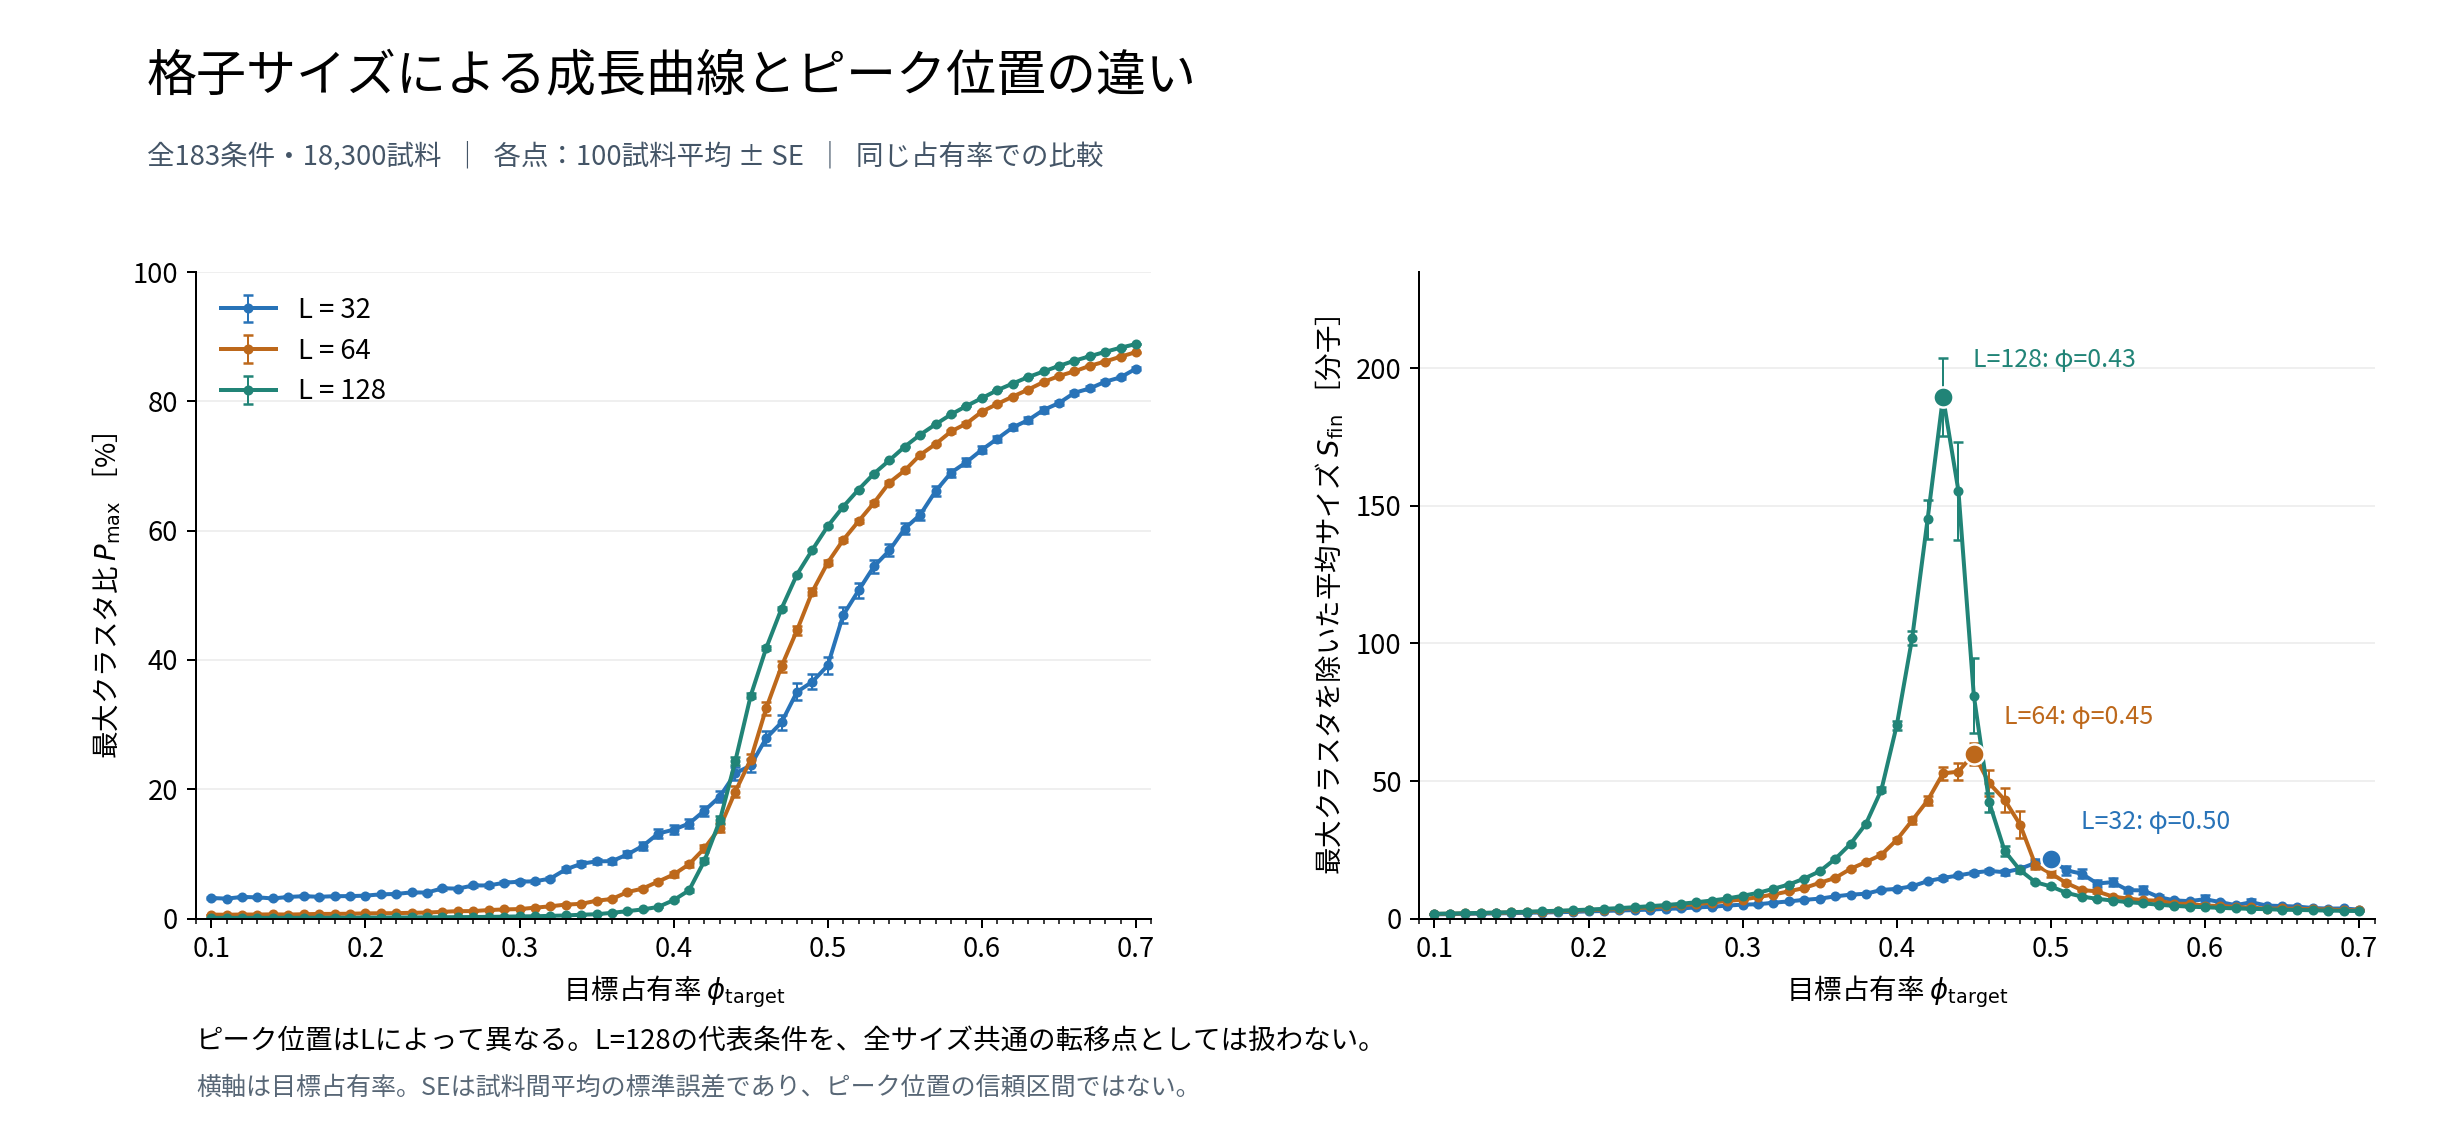

In [6]:
from IPython.display import display, Image

display(Image(filename=str(OUTPUT / "finite_size_overview.png")))


## ② 代表条件の選定根拠
L=128では、低占有率側・平均Sfin最大点・高占有率側として0.41・0.43・0.60を選びます。

この選定は既存データを見て設定した記述的な規則です。H2末端割合の曲線の値は条件選定に使っていません。

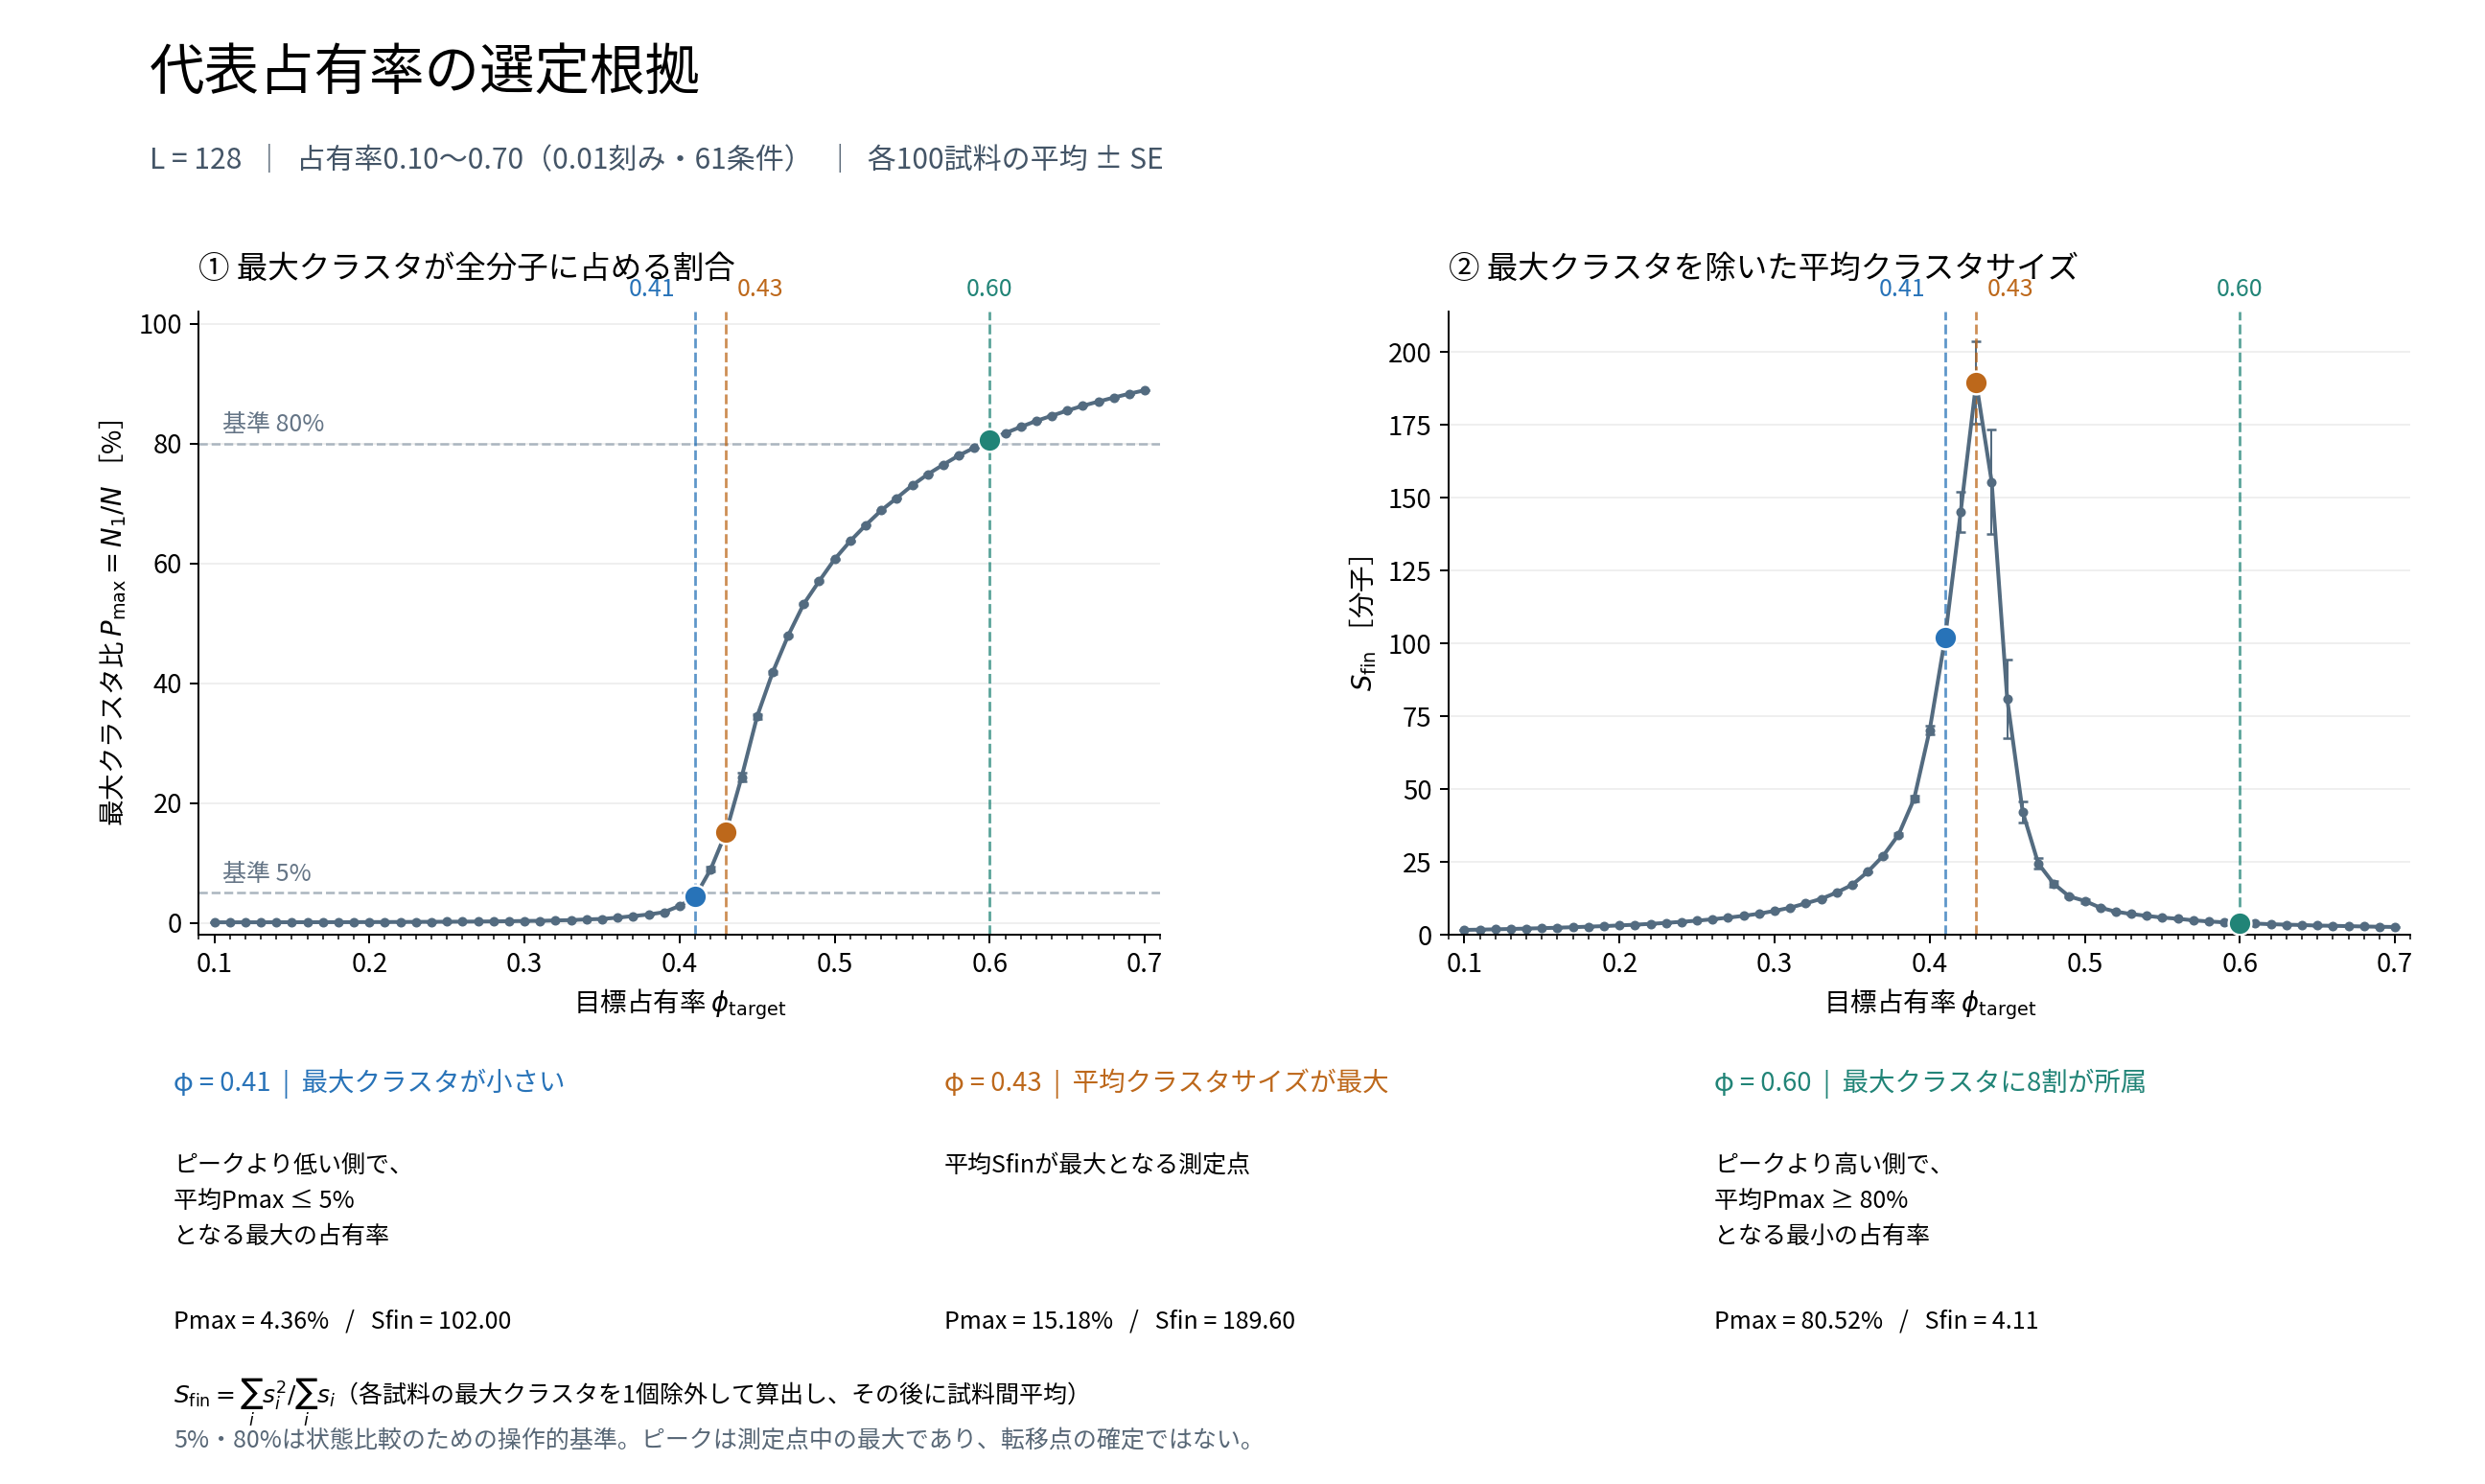

In [7]:
display(Image(filename=str(OUTPUT / f"selection_basis_L{L}.png")))


## 共有するファイル
Driveの出力フォルダからPNG2枚と `run_metadata.json` を共有できます。SVGは報告資料への貼り付け・拡大用です。

Sfinは各試料で最大クラスタを1個除き、残ったクラスタのサイズ二乗和をサイズ和で割った量を、試料間で平均しています。SEは試料間平均の不確かさで、ピーク位置の信頼区間ではありません。横軸は目標占有率です。

元のH2報告ノートブックとは別のノートです。H2図の描画条件は、このノートの実行では変更されません。